## 1. Import thư viện và cấu hình

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Tải và tiền xử lý CIFAR-10

In [2]:
FAST_MIRROR = (
    'https://huggingface.co/datasets/VerisimilitudeX/cifar10/'
    'resolve/main/cifar-10-python.tar.gz'
)
try:
    tf.keras.utils.get_file(
        fname='cifar-10-batches-py-target',
        origin=FAST_MIRROR,
        file_hash='6d958be074577803d12ecdefd02955f39262c83c16fe9348329d7fe0b5c001ce',
        hash_algorithm='sha256',
        extract=True,
    )
    print('Đã chuẩn bị dữ liệu từ mirror/cache nhanh.')
except Exception as error:
    print('Mirror không khả dụng, chuyển sang nguồn CIFAR-10 gốc:', error)

(X_train, y_train_raw), (X_test, y_test_raw) = datasets.cifar10.load_data()

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

y_train = to_categorical(y_train_raw, 10)
y_test = to_categorical(y_test_raw, 10)

class_names = [
    'Máy bay', 'Ô tô', 'Chim', 'Mèo', 'Hươu',
    'Chó', 'Ếch', 'Ngựa', 'Tàu thủy', 'Xe tải'
]

print('Train:', X_train.shape, y_train.shape)
print('Test :', X_test.shape, y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Đã chuẩn bị dữ liệu từ mirror/cache nhanh.
Train: (50000, 32, 32, 3) (50000, 10)
Test : (10000, 32, 32, 3) (10000, 10)


## 3. Xem một số ảnh mẫu

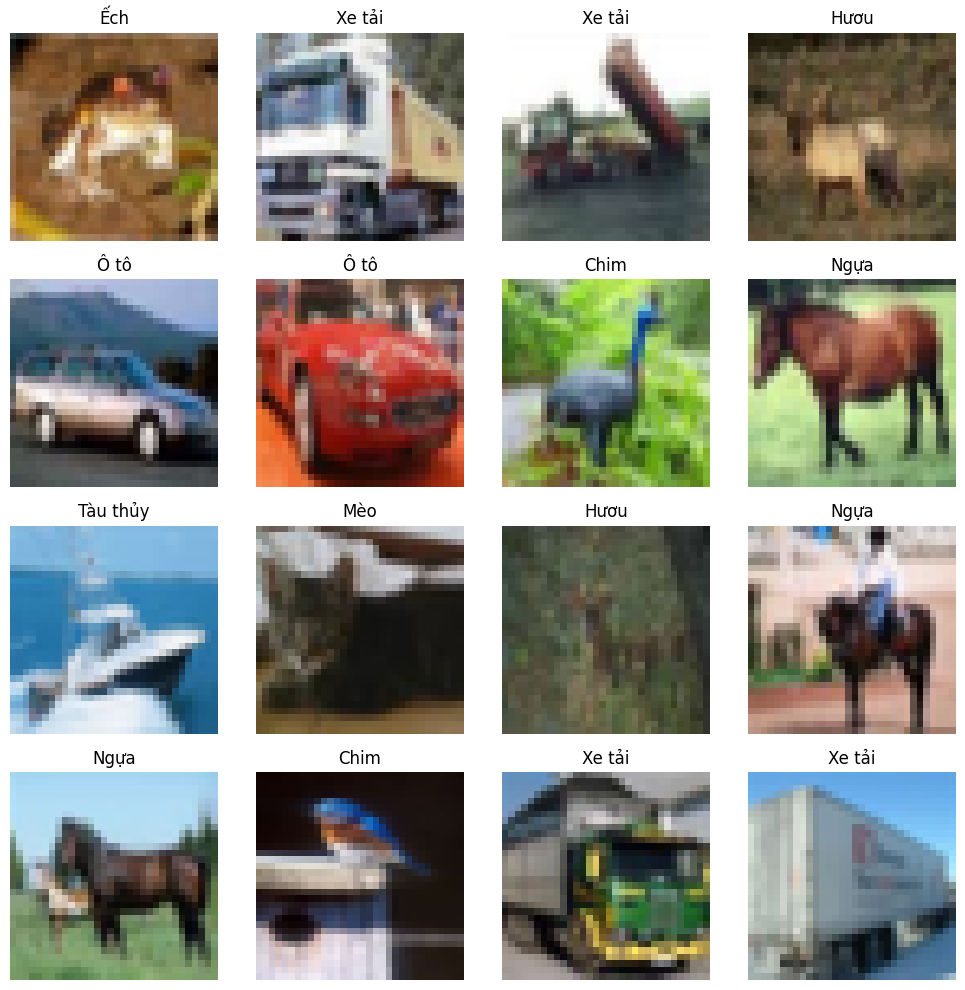

In [3]:
plt.figure(figsize=(10, 10))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[int(y_train_raw[i, 0])])
    plt.axis('off')
plt.tight_layout()
plt.show()

## 4. Xây dựng mô hình CNN

In [4]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,341,226 (5.12 MB)

 Trainable params: 1,341,226 (5.12 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Huấn luyện mô hình

In [5]:
EPOCHS = 30
BATCH_SIZE = 64

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    )
]

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 24s 15ms/step - accuracy: 0.3674 - loss: 1.6908 - val_accuracy: 0.5229 - val_loss: 1.3161
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5451 - loss: 1.2615 - val_accuracy: 0.6098 - val_loss: 1.0676
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6191 - loss: 1.0715 - val_accuracy: 0.6682 - val_loss: 0.9275
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6609 - loss: 0.9528 - val_accuracy: 0.7014 - val_loss: 0.8459
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6910 - loss: 0.8733 - val_accuracy: 0.7209 - val_loss: 0.7893
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7144 - loss: 0.8103 - val_accuracy: 0.7282 - val_loss: 0.7793
Epoch 7/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7310 - loss: 0.7637 - val_accuracy: 0.7503 - val_loss: 0.7155
Epoch 8/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7474 - loss: 0.7198 - val_accuracy: 

## 6. Vẽ lịch sử huấn luyện

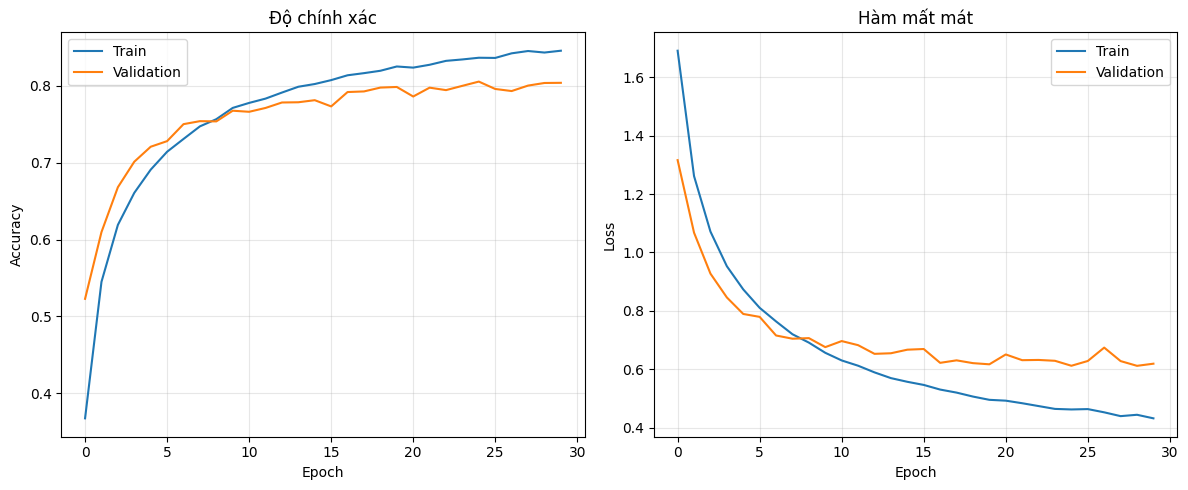

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set(title='Độ chính xác', xlabel='Epoch', ylabel='Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set(title='Hàm mất mát', xlabel='Epoch', ylabel='Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Đánh giá trên tập kiểm tra

In [7]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.2%}')

pred_probs = model.predict(X_test, batch_size=128, verbose=0)
y_pred = np.argmax(pred_probs, axis=1)
y_true = y_test_raw.ravel()

print('\nClassification report:')
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

Test loss: 0.6294
Test accuracy: 80.01%

Classification report:
              precision    recall  f1-score   support

     Máy bay     0.8192    0.8200    0.8196      1000
        Ô tô     0.9169    0.8720    0.8939      1000
        Chim     0.7281    0.6990    0.7133      1000
         Mèo     0.6711    0.5610    0.6111      1000
        Hươu     0.7897    0.7510    0.7699      1000
         Chó     0.6789    0.7780    0.7251      1000
         Ếch     0.8132    0.8750    0.8430      1000
        Ngựa     0.8130    0.8650    0.8382      1000
    Tàu thủy     0.9041    0.8860    0.8949      1000
      Xe tải     0.8638    0.8940    0.8786      1000

    accuracy                         0.8001     10000
   macro avg     0.7998    0.8001    0.7988     10000
weighted avg     0.7998    0.8001    0.7988     10000



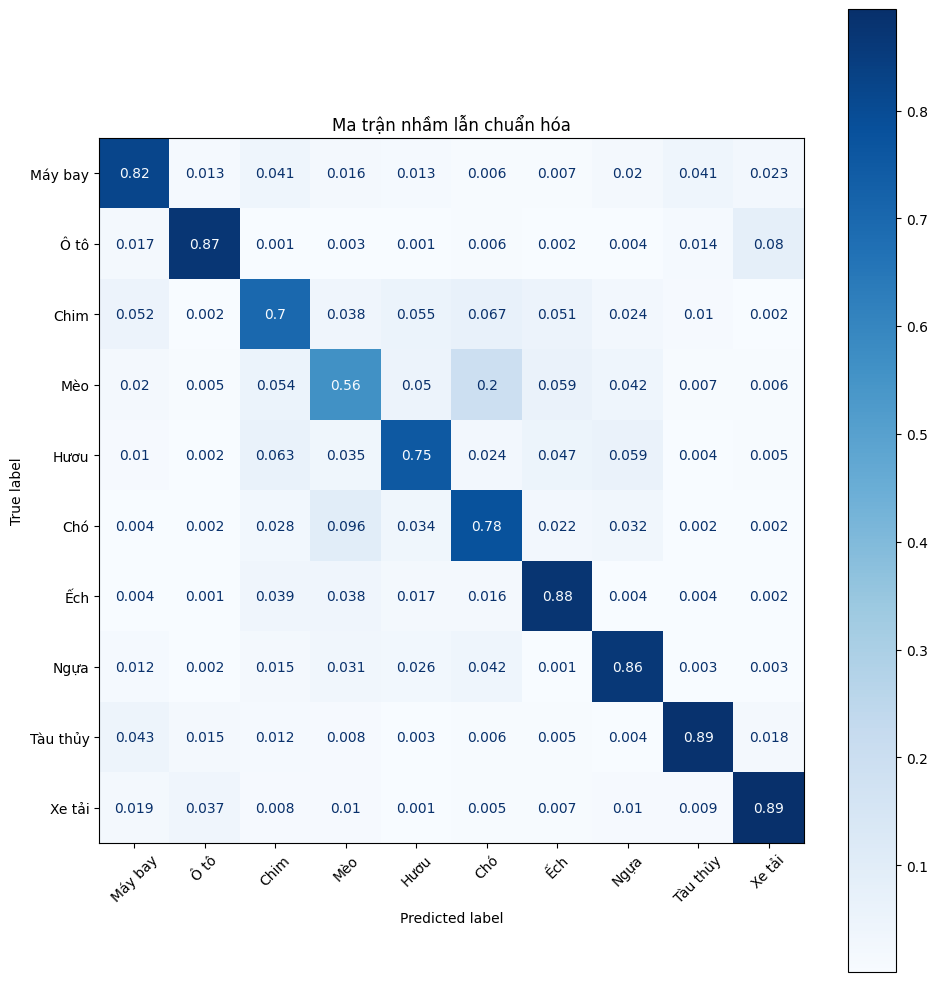

In [8]:
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=class_names,
    cmap='Blues', normalize='true', xticks_rotation=45, ax=ax
)
ax.set_title('Ma trận nhầm lẫn chuẩn hóa')
plt.tight_layout()
plt.show()

## 8. Hiển thị dự đoán

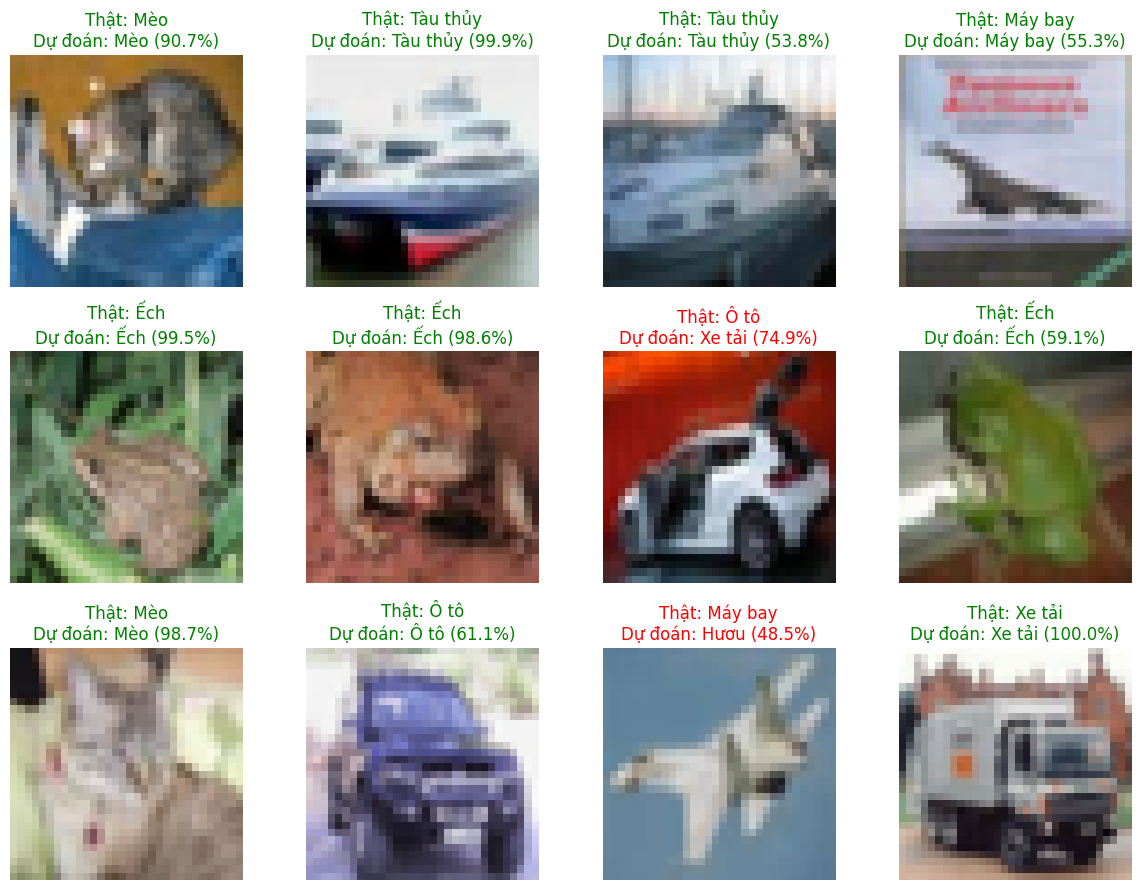

In [9]:
def plot_predictions(indices):
    indices = list(indices)
    cols = 4
    rows = int(np.ceil(len(indices) / cols))
    plt.figure(figsize=(12, 3 * rows))

    for position, index in enumerate(indices, start=1):
        true_id = int(y_test_raw[index, 0])
        pred_id = int(y_pred[index])
        confidence = float(pred_probs[index, pred_id])
        color = 'green' if pred_id == true_id else 'red'

        plt.subplot(rows, cols, position)
        plt.imshow(X_test[index])
        plt.title(
            f'Thật: {class_names[true_id]}\n'
            f'Dự đoán: {class_names[pred_id]} ({confidence:.1%})',
            color=color
        )
        plt.axis('off')

    plt.tight_layout()
    plt.show()

plot_predictions(range(12))

## 9. Lưu mô hình

In [10]:
model.save('cifar10_cnn.keras')
print('Đã lưu mô hình vào cifar10_cnn.keras')

Đã lưu mô hình vào cifar10_cnn.keras
